# just_drop vs just_drop_hal：处理 PPS

同一块 ESP32-C3、同一 AP、同一台 TR3000 上比较两条丢弃路径。HAL 是 `just_drop_hal`（应用层 UDP:8080 丢弃并计 `drop`）；XDP 是 `just_drop` 固件加冷表 `just_drop.elf`（Wi-Fi 入口 `XDP_DROP` 计 `drop`）。计的是进入各自丢弃路径的包，不是无线物理层收到的包。

三个指标分开读：

1. **平均处理 PPS**。单轮 `(C_end − C_start) / (t_end − t_start)`，再对有效轮取均值。计数下降的轮作废。柱从 0 起，长度就是速率。
2. **1 s 相对 Allan deviation**。等间隔计数序列上的重叠两样本 ADEV，除以该轮平均 PPS。两边都在 8% 附近，纵轴不从 0 起，否则看不出差距。这是固定 1 s 节拍，不是正式协议里的随机三点局部 ADEV。
3. **跨轮 CV**。有效轮平均 PPS 的 `SD / mean`。HAL 接近 0，这条轴从 0 起。

这批数据是 `formal.experiment_*` 里的 `run_kind=pilot`：3 个配对块，每臂 40 s，约 1 s 读一次 `drop`。发包是 TR3000 上的满速小 UDP（`udp_blast`）；`sender_target_pps` 是主机提交速率，不代替处理 PPS。均值和 ADEV 的 95% 区间用轮间 Student *t*。n = 3，区间只描述这批 pilot。

复现：Mac 上 `cargo xtask agent --listen 0.0.0.0:9240 --no-monitor`（cwd = `xpost/`）；TR3000 上 `./xpost-test`。本笔记只读库。


nan@192.168.110.96:5432/postgres schema=formal
runs=6 samples=252
hal: valid=3/3  PPS=2728  ADEV@1s=8.06% (7.79–8.33)  CV=0.26%  per-run=[2725, 2736, 2724]
xdp: valid=3/3  PPS=8684  ADEV@1s=8.82% (8.44–9.21)  CV=2.56%  per-run=[8907, 8463, 8681]


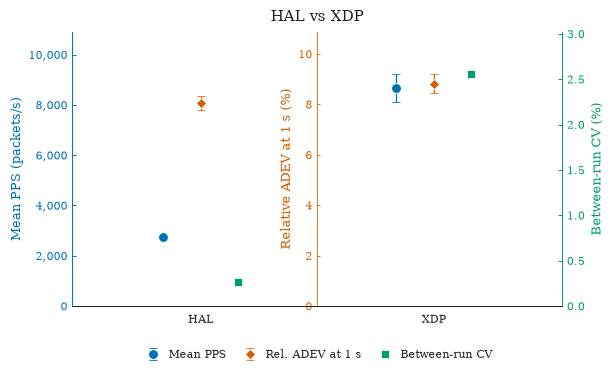

In [3]:
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import (
    cv_bootstrap_ci,
    figure1_summary,
    load_counter_samples,
    load_runs,
    mean_across_runs,
    mean_pps,
    mean_t_ci,
    overlapping_relative_adev,
    summarize_variant,
)

plt.ioff()
plt.close("all")
print(dsn_summary())

runs = load_runs(run_kind="pilot")
assert len(runs), "formal.experiment_runs 无 pilot 行：先在 TR3000 跑 ./xpost-test，且 .env 设 PGSCHEMA=formal"
samples = load_counter_samples(runs["run_id"].tolist())
print(f"runs={len(runs)} samples={len(samples)}")

by_variant = defaultdict(list)
adev_runs = defaultdict(list)

for _, row in runs.iterrows():
    sub = samples[samples["run_id"] == row["run_id"]].sort_values("time_ns")
    t_ns = sub["time_ns"].tolist()
    c = sub["counter_value"].tolist()
    variant = row["variant"]
    by_variant[variant].append(
        mean_pps(t_ns, c, run_id=row["run_id"], variant=variant, pair_id=int(row["pair_id"]))
    )
    adev = overlapping_relative_adev(t_ns, c)
    if adev:
        adev_runs[variant].append({tau: d["adev"] for tau, d in adev.items()})

summaries = {v: summarize_variant(rs) for v, rs in by_variant.items()}
adev_pool = {v: mean_across_runs(rows) for v, rows in adev_runs.items()}


def _at(pool, tau=1.0):
    row = pool.get(tau) or {}
    return row.get("mean"), (row.get("lo"), row.get("hi"))


for v, s in summaries.items():
    a_mean, (a_lo, a_hi) = _at(adev_pool.get(v, {}))
    print(
        f"{v}: valid={s['n_valid']}/{s['n_total']}  "
        f"PPS={s['mean_pps']:.0f}  ADEV@1s={100 * a_mean:.2f}% "
        f"({100 * a_lo:.2f}–{100 * a_hi:.2f})  "
        f"CV={100 * s['cv']:.2f}%  "
        f"per-run={[round(x) for x in s['per_run_pps']]}"
    )

hal, xdp = summaries.get("hal", {}), summaries.get("xdp", {})
hal_pps = hal.get("per_run_pps") or []
xdp_pps = xdp.get("per_run_pps") or []
_, hal_pps_lo, hal_pps_hi = mean_t_ci(hal_pps)
_, xdp_pps_lo, xdp_pps_hi = mean_t_ci(xdp_pps)
hal_cv, _, _ = cv_bootstrap_ci(hal_pps)
xdp_cv, _, _ = cv_bootstrap_ci(xdp_pps)
hal_a, hal_a_ci = _at(adev_pool.get("hal", {}))
xdp_a, xdp_a_ci = _at(adev_pool.get("xdp", {}))

fig, _ = figure1_summary(
    hal_mean_pps=hal.get("mean_pps", float("nan")),
    xdp_mean_pps=xdp.get("mean_pps", float("nan")),
    hal_pps_ci=(hal_pps_lo, hal_pps_hi),
    xdp_pps_ci=(xdp_pps_lo, xdp_pps_hi),
    hal_adev_1s=hal_a,
    xdp_adev_1s=xdp_a,
    hal_adev_ci=hal_a_ci,
    xdp_adev_ci=xdp_a_ci,
    hal_cv=hal_cv,
    xdp_cv=xdp_cv,
    title="HAL vs XDP",
)
display(fig)
plt.close(fig)


## 这批 pilot 能说什么

三对、每臂 40 s。数字是三轮均值。

**速率差在电平，不在抖动。** HAL 平均 2 728 packets/s（三轮 2 725、2 736、2 724），XDP 平均 8 684（8 907、8 463、8 681），大约 3.2 倍。主机提交速率在 8.6k–9.3k。HAL 三轮几乎贴在 2.73k，提交速率变了它也不动，说明这条应用层路径已经饱和，多出来的包在计数点之前就没了。XDP 每一轮都吃进该轮提交量的大约 98.7%（8 907/9 026、8 463/8 568、8 681/8 800），所以在这档满速小包下，瓶颈在发包端，不在 XDP 丢弃路径。

**1 s 稳定性两边差不多。** 相对 ADEV 是 8.06%（HAL，95% 区间 7.79–8.33）对 8.82%（XDP，8.44–9.21）。差距大约 0.8 个百分点，相对 3 倍的 PPS 差可以忽略。更长窗口上两边一起下降，16 s 都到 1.4% 左右，形状一样。泊松过程在这个计数率下 1 s 相对起伏只有大约 1–2%，实测 8% 比它大，多出来的抖动更像共有的发包或无线，不像两条丢弃路径各自的差异。

**跨轮：HAL 稳，XDP 的散差跟着发包走。** HAL 的 CV 是 0.26%。XDP 的 CV 是 2.6%，但这三轮的 PPS 和该轮 `sender_target_pps` 成比例，不是固件自己漂。n = 3、窗口 40 s，不能拿去对预注册的 12 块、15 分钟判据。
